# Phase 1: Support set of V2 by condensation (Hart and Gates)

## Section 1 - Purpose and decision rule

In the test of Phase 1, arm_2 is the weakest piece (0.416). Of its patches, 43.1% are labelled arm_1 and 14.6% background. The two arms have the same tube and differ only by the hand. Phase 2 must fix the identity of each piece when it is loose, picked and mounted, so arm_2 must be seen with its own identity before it is mounted.

This notebook adds to the current support set A examples taken from the annotated frames of assembly_2. They are chosen patch by patch, by a rule fixed before any result. assembly_2 is a real assembly, recorded with the same camera and the same procedure as the use.

The rule is the condensed nearest neighbour of Hart (1968, p. 515), followed by the reduction of Gates (1972, p. 432). Hart classifies each sample with the current store and adds it only if it is classified wrongly, until a full pass adds nothing. The result classifies every sample correctly, but it is not in general the smallest such set. Gates then removes the added samples one at a time, and keeps a removal only if every sample is still classified correctly.

Two things differ from Hart. The store starts from A instead of a single sample, and nothing in A is ever removed. An incremental search can keep adding samples that become available after training, with the same criterion (García et al. 2012, Sect. 3.1.1).

The candidates are the patches of the 10 pieces in the 32 annotated frames of assembly_2, labelled with the rule of the pipeline. Hand and background are not candidates. They are presented in time order, and in row order within a frame. Gates removes in the order in which Hart added.

This differs from the selection of the support-set study on V2 (Section 6) in four ways. Only single patches added here can be removed, never examples of A. A removal is accepted only if no source patch becomes wrong, with no score to maximize and no tolerance. The source frames come from a real assembly, not from reference frames unlike the use. The arms are always separate classes.

The risk is the same. Condensation keeps the points near the boundaries between classes and can lose accuracy on new data (García et al. 2012, Sect. 3.1.2). Consistency is checked only on the patches of the pieces, not on the background of assembly_2; pieces predicted on the background are caught by the condition on the IoU.

Decision rule. One support set is judged: A plus the patches kept by Gates. It is measured once on the 31 annotated frames of assembly_1 and kept only if three conditions hold.

First, arm_2 is seen in more frames when it is loose or in hand: the paired 95% interval of the difference in the number of frames lies above 0. A piece is seen in a frame when at least one of its patches has its label. One patch is the only value valid for any number of patches Phase 2 will require.

Second, no piece loses, in any state, a frame where A sees it. In hand and at the mounting each piece has one frame, so a lost frame is a lost event.

Third, for every piece and for the mIoU over the 10 pieces, the lower end of the paired 95% interval of the difference in IoU lies above −Δ. Δ is fixed in Section 4 from A alone, before the new support set exists (Piaggio et al. 2012, eAppendix).

The intervals use the paired block bootstrap of the test: blocks of 3 frames, 1000 resamples, seed 0. If a condition fails, A is kept. A plus all the patches added by Hart is measured only as a description, and cannot replace the decision.

After this notebook, assembly_1 is a development set like assembly_2, and its values are optimistic. A new support set will be judged only by the final test on a new recording.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Hart 1968, p. 515: consistent subset and the condensed nearest neighbour rule, which does not in general find the minimal one.

Gates 1972, pp. 432-433: the reduced nearest neighbour rule; it finds the minimal consistent subset when the set of Hart contains it.

García et al. 2012, Sect. 3.1.1: incremental search, which can keep adding samples that become available later. Sect. 3.1.2: condensation keeps border points and can lose accuracy on new data.

Piaggio et al. 2012, eAppendix ("Interpretation", "Choice of the noninferiority margin Δ"): the margin and the confidence level are fixed in advance and justified.

Support-set study on V2 (phase_1_support_set_v2_study.ipynb), Sections 6 and 8.5: the decremental selection by objects and why it failed.

Phase 1 test (phase_1_test.ipynb), Sections 3 and 7: the evaluation frames, the paired block bootstrap and the errors of arm_2.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, settings and frames in one place. The values are those of the pipeline and of the test.

Two lists of frames are used, and they never mix. The 32 annotated frames of assembly_2 are the source: the new prototypes come only from them. The 31 annotated frames of assembly_1 are the evaluation: the decision is made only on them.

The margin Δ is empty here. It is fixed in Section 4 from A alone, and Section 5 does not run until it is set.

In [1]:
# 2.1 Imports, paths and shared module
import json
import sys
import time
import platform
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_1_events.json"                       # states of the pieces (Section 4)
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_1.mp4"                      # Section 8, description only
IPHONE_DIR = PROJECT_ROOT / "data" / "raw_videos" / "iphone_scene"                        # Section 10, exploratory
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"  # support set A, read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_support_set_hart"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "EVENTS_PATH": EVENTS_PATH,
                   "VIDEO_PATH": VIDEO_PATH, "PROTOTYPES_PATH": PROTOTYPES_PATH}.items():
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

from perception.classes import CLASS_NAMES, BACKGROUND_LABEL, HAND_LABEL, PIECE_LABELS, IGNORE_ID, CLASS_COLORS
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (load_patch_prototypes, patch_prototypes, sort_by_class, l2_normalize,
                                   class_similarities_gpu, assign_labels)
from perception.metrics import confusion_matrix, frame_iou, frame_miou, bootstrap_class_iou, bootstrap_miou, percentile_interval
from perception.visualization import render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_1_events.json
[OK] VIDEO_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\assembly_1.mp4
[OK] PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\patch_prototypes.npz


In [ ]:
# 2.2 Settings
# Values of the pipeline and of the test (phase_1_test.ipynb, Section 2.5).
DEVICE, DTYPE = "cuda", torch.bfloat16
INPUT_SIZE, PATCH_SIZE = (1024, 1024), 16
MIN_LABEL_COVERAGE = 0.5        # labelling rule of the pipeline (Section 5)
MARGIN = 0.0                    # background margin of V2 (margin study)
GT_LABELS = PIECE_LABELS | {HAND_LABEL}

N_BOOTSTRAP, BLOCK, RANDOM_SEED = 1000, 3, 0     # paired block bootstrap of the test (Section 7)
MIN_SEEN_PATCHES = 1            # a piece is seen with at least one patch of its label: valid for any threshold of Phase 2

DELTA = 0.014                   # non-inferiority margin on the IoU: change of A between assembly_2 and assembly_1 (Section 4.3)                    # non-inferiority margin on the IoU, fixed in Section 4 from A alone, before Section 5

MIN_BLOB_PATCHES = 5            # smallest blob with a text label in the overlays, as in the pipeline
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [3]:
# 2.3 Source frames (assembly_2, where the patches come from) and evaluation frames (assembly_1, where the decision is made)
# Source: the 32 annotated frames of assembly_2 (support-set study on V2, Section 2.5), in time order.
_SOURCE = [(3, "table"), (4, "pick"), (5, "mount"), (8, "table"), (10, "pick"), (12, "mount"), (17, "table"),
           (18, "pick"), (19, "mount"), (24, "table"), (26, "pick"), (28, "pick"), (30, "mount"), (33, "mount"),
           (37, "table"), (42, "pick"), (43, "mount"), (46, "table"), (50, "pick"), (51, "mount"), (52, "table"),
           (53, "pick"), (54, "mount"), (57, "table"), (59, "pick"), (60, "mount"), (63, "pick"), (65, "mount"),
           (68, "table"), (70, "pick"), (73, "mount"), (77, "table")]
SOURCE_FRAMES = [{"frame": f"assembly_2_f{i:04d}", "index": i, "moment": m} for i, m in _SOURCE]

# Evaluation: the 31 test frames of assembly_1 (phase_1_test.ipynb, Section 2.6), with the piece of each pick and mount.
_EVALUATION = [(2, "table", None), (4, "pick", "base"), (5, "mount", "base"), (8, "table", None), (11, "pick", "body"),
               (12, "mount", "body"), (16, "table", None), (18, "pick", "mouth"), (19, "mount", "mouth"), (25, "table", None),
               (27, "pick", "moustache"), (29, "pick", "nose"), (31, "mount", "nose"), (33, "mount", "nose+moustache"),
               (37, "table", None), (39, "pick", "eyes"), (40, "mount", "eyes"), (43, "table", None), (45, "pick", "ear"),
               (47, "mount", "ear"), (48, "pick", "ear"), (52, "mount", "ear"), (54, "table", None), (55, "pick", "arm_1"),
               (57, "mount", "arm_1"), (60, "pick", "arm_2"), (62, "mount", "arm_2"), (65, "table", None),
               (67, "pick", "hat"), (68, "mount", "hat"), (73, "table", None)]
EVAL_FRAMES = [{"frame": f"assembly_1_f{i:04d}", "index": i, "moment": m, "piece": p} for i, m, p in _EVALUATION]

for item in SOURCE_FRAMES + EVAL_FRAMES:
    item["image_path"] = FRAMES_DIR / f"{item['frame']}.jpg"
    item["json_path"] = FRAMES_DIR / f"{item['frame']}.json"
    check_annotation(item["image_path"], item["json_path"])
assert {sequence_of(f["frame"]) for f in SOURCE_FRAMES} == {"assembly_2"}
assert {sequence_of(f["frame"]) for f in EVAL_FRAMES} == {"assembly_1"}
print(f"{len(SOURCE_FRAMES)} source frames, {len(EVAL_FRAMES)} evaluation frames")
display(pd.DataFrame({"source": pd.Series([f["moment"] for f in SOURCE_FRAMES]).value_counts(),
                      "evaluation": pd.Series([f["moment"] for f in EVAL_FRAMES]).value_counts()})
        .reindex(["table", "pick", "mount"]))

32 source frames, 31 evaluation frames


,source,evaluation
table,10,9
pick,11,11
mount,11,11


In [4]:
# 2.4 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


Observation 2: Every path exists. The source has 32 frames of assembly_2, 10 at the table, 11 at the pick and 11 at the mounting. The evaluation has 31 frames of assembly_1, 9 at the table, 11 at the pick and 11 at the mounting. Every frame has its image and its annotation, with only official classes.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 2:

Support-set study on V2, Section 2.5: the 32 frames of assembly_2.

Phase 1 test, Sections 2.5 and 2.6: the settings and the 31 frames of assembly_1.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Support set A and regression check

A is the support set of the pipeline, loaded from the saved prototypes. Its reference frames must come from neither assembly_1 nor assembly_2.

The features of the 63 frames are computed once and kept in memory, so that Sections 4 to 8 never run C-RADIO again on them.

A must give back the test of Phase 1 exactly: the same labels on the 31 frames of assembly_1, and a mIoU of 0.765 over the 10 pieces. Everything that follows compares with this A.

In [5]:
# 3.1 Support set A: the saved V2 prototypes of the pipeline (sorted by class)
saved = load_patch_prototypes(PROTOTYPES_PATH)
A_VECTORS, A_OWNERS = saved["prototypes"], saved["owners"]
reference_sequences = {sequence_of(r["frame"]) for r in saved["metadata"]["reference_frames"]}
assert saved["class_names"] == CLASS_NAMES
assert not reference_sequences & {"assembly_1", "assembly_2"}, "A must not use source or evaluation recordings"
assert np.all(A_OWNERS[1:] >= A_OWNERS[:-1]), "Saved prototypes are expected sorted by class"

fingerprint = hashlib.sha256(PROTOTYPES_PATH.read_bytes()).hexdigest()[:12]
print(f"A: {len(A_VECTORS)} prototypes from {len(reference_sequences)} reference sequences, SHA-256 {fingerprint}")
display(pd.Series(np.bincount(A_OWNERS, minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="prototypes").to_frame().T)
A_GPU = tuple(torch.as_tensor(x, device=DEVICE) for x in (A_VECTORS, A_OWNERS))

A: 39125 prototypes from 6 reference sequences, SHA-256 ab0f13579f17


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,37864,302,201,52,32,52,29,35,28,33,15,482


In [6]:
# 3.2 Features and ground truth of the 63 frames, computed once
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
assert extractor.patch_size == PATCH_SIZE

start = time.time()
for item in SOURCE_FRAMES + EVAL_FRAMES:
    item["features"], size = extractor.extract(Image.open(item["image_path"]).convert("RGB"))
    assert tuple(size) == INPUT_SIZE
    pixel_map = rasterize_annotation(item["json_path"], GT_LABELS, INPUT_SIZE)
    item["gt"], item["fractions"] = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)
print(f"{len(SOURCE_FRAMES) + len(EVAL_FRAMES)} frames in {time.time() - start:.0f} s")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

63 frames in 28 s


In [7]:
# 3.3 Regression check: A on assembly_1 gives back the test of Phase 1 (labels and mIoU)
EXCLUDED = [set() for _ in EVAL_FRAMES]
test_predictions = np.load(PROJECT_ROOT / "outputs" / "phase_1_test" / "predictions.npz")   # read only

different = 0
for item in EVAL_FRAMES:
    item["labels"] = {"A": assign_labels(class_similarities_gpu(item["features"], *A_GPU), MARGIN)}
    different += int((item["labels"]["A"] != test_predictions[f"{item['frame']}__labels"]).sum())
CONF = {"A": [confusion_matrix(item["gt"], item["labels"]["A"]) for item in EVAL_FRAMES]}

miou_a = frame_miou(CONF["A"], EXCLUDED)
print(f"Patches labelled differently from the test: {different}")
print(f"mIoU of A over the 10 pieces on assembly_1: {miou_a:.3f} (test: 0.765)")
assert different == 0 and round(miou_a, 3) == 0.765

Patches labelled differently from the test: 0
mIoU of A over the 10 pieces on assembly_1: 0.765 (test: 0.765)


Observation 3: A has 39,125 prototypes from 6 reference sequences, none of them assembly_1 or assembly_2; arm_2 has 15 and mouth 28. The features of the 63 frames take 28 s.

On the 31 frames of assembly_1, A labels every patch exactly as the test of Phase 1 (0 differences), and its mIoU over the 10 pieces is 0.765. The comparison of the next sections starts from the test itself.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

Pipeline (phase_1_perception.ipynb), Section 6: the V2 prototypes saved with their metadata.

Phase 1 test, Sections 4.2 and 7.2: the ground truth of the 31 frames and the saved predictions.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - States of the pieces and margin

This section uses A alone. It fixes what the decision rule needs before any new prototype exists.

The state of every piece in every frame of assembly_1 comes from the event log, with the definitions of Phase 2. A piece is loose before the start of its contact, in hand until its insert, mounting until the hands leave the figure, and mounted after. The start of the contact is the touch, or the first frame the piece is seen in hand when the touch is outside the frame. A piece enters a frame only if it is annotated there.

These definitions give back the rules that chose the frames (test, Section 3): the piece of a pick frame is in hand, the piece of a mount frame is mounting. The one exception is f0031, the nose threaded into the moustache in the hand. The test counts it as a mounting, but the nose is still in the hand, not on the figure. For Phase 2 it is in hand.

The two ears share one class. When one ear is in hand or mounting, that state is the state of the class in that frame. A patch of the other ear can still make the class seen; this is a limit of counting by class.

Then the margin. The candidate value is the change of A between two recordings of the same procedure: 0.779 on assembly_2, 0.765 on assembly_1. Cell 4.3 translates it into patches for each piece, so that it can be judged by what it means. Δ is then written in the configuration and committed before Section 5 is run.

Condition 1 is revised here, before any new prototype exists. With A, arm_2 loose is already seen with at least one patch in 18 of 21 frames, often through one or two patches of its closed hand, while the rest of the arm is labelled arm_1. Seen frames would leave at most 4 frames to gain and would not measure the identity of the arm. Condition 1 therefore counts the patches of arm_2 labelled arm_2 in the frames where it is loose or in hand. The reason is a property of the measure on A, not a result of the new support set.

In [8]:
# 4.1 State of every piece in every evaluation frame, from the event log of assembly_1
EVENT_LOG = json.loads(EVENTS_PATH.read_text())
GRID = 30                                       # extracted frame fNNNN is video frame 30 * NNNN (extract_frames.py)
STATES = ["loose", "in hand", "mounting", "mounted"]
ACTIVE = {"in hand", "mounting"}
PIECES = [c for c in CLASS_NAMES if c in PIECE_LABELS]
JOIN_IN_HAND = {31}                             # f0031: nose threaded into the moustache in the hand (test, Section 3)


def event_state(event, t):
    """State of one piece at video frame t: loose before its contact, in hand until its insert,
    mounting until the hands leave the figure, mounted after."""
    start = event["touch"] if event["touch"] is not None else event["first_seen"]
    if t < start:
        return "loose"
    if t < event["insert"]:
        return "in hand"
    if t <= event["hands_off"]:
        return "mounting"
    return "mounted"


def piece_state(piece, t):
    """State of a class at frame t. With two instances (the ears), an active state wins over a passive one."""
    states = {event_state(e, t) for e in EVENT_LOG["events"] if e["piece"] == piece}
    active = states & ACTIVE
    assert len(active) <= 1, f"{piece} at video frame {t}: two instances active at once"
    if active:
        return active.pop()
    assert len(states) == 1, f"{piece} at video frame {t}: instances in different passive states {states}"
    return states.pop()


for item in EVAL_FRAMES:
    t = GRID * item["index"]
    item["states"] = {p: piece_state(p, t) for p in PIECES if (item["gt"] == CLASS_NAMES.index(p)).any()}
    if item["moment"] != "table":                # check against the rules that chose the frame
        expected = "in hand" if item["moment"] == "pick" or item["index"] in JOIN_IN_HAND else "mounting"
        for p in item["piece"].split("+"):
            assert item["states"].get(p) == expected, f"{item['frame']}: {p} is {item['states'].get(p)}, expected {expected}"

presence = pd.DataFrame([{"piece": p, "state": s} for item in EVAL_FRAMES for p, s in item["states"].items()])
display(pd.crosstab(presence["piece"], presence["state"]).reindex(index=PIECES, columns=STATES, fill_value=0))

state,loose,in hand,mounting,mounted
piece,,,,
body,2,1,1,25
base,0,1,1,28
hat,26,1,1,1
eyes,14,1,1,14
ear,18,2,2,9
nose,11,2,1,16
moustache,8,3,1,16
mouth,2,1,1,22
arm_1,19,1,1,6


In [9]:
# 4.2 Frames where A sees each piece, by state (seen = at least MIN_SEEN_PATCHES patches of the piece with its label)
def seen(item, labels, piece):
    c = CLASS_NAMES.index(piece)
    return int(((item["gt"] == c) & (labels == c)).sum()) >= MIN_SEEN_PATCHES


rows = [{"piece": p, "state": s, "seen": seen(item, item["labels"]["A"], p)}
        for item in EVAL_FRAMES for p, s in item["states"].items()]
seen_a = pd.DataFrame(rows)
table = seen_a.groupby(["piece", "state"])["seen"].agg(["sum", "count"])
display((table["sum"].astype(str) + " / " + table["count"].astype(str)).unstack().reindex(index=PIECES, columns=STATES))

arm_2_early = seen_a[(seen_a["piece"] == "arm_2") & seen_a["state"].isin(["loose", "in hand"])]
print(f"arm_2 loose or in hand: seen by A in {int(arm_2_early['seen'].sum())} of {len(arm_2_early)} frames")

state,loose,in hand,mounting,mounted
piece,,,,
body,2 / 2,1 / 1,1 / 1,25 / 25
base,NaN,1 / 1,1 / 1,28 / 28
hat,25 / 26,1 / 1,1 / 1,1 / 1
eyes,11 / 14,1 / 1,1 / 1,14 / 14
ear,18 / 18,2 / 2,1 / 2,9 / 9
nose,11 / 11,1 / 2,1 / 1,16 / 16
moustache,8 / 8,3 / 3,1 / 1,15 / 16
mouth,1 / 2,1 / 1,1 / 1,22 / 22
arm_1,19 / 19,1 / 1,1 / 1,6 / 6


arm_2 loose or in hand: seen by A in 18 of 22 frames


In [10]:
# 4.3 What the candidate margin means in patches, for each piece (A only)
VALIDATION_MIOU = 0.779         # A on the 32 frames of assembly_2 (support-set study on V2, Observation 8.2)
DELTA_CANDIDATE = round(VALIDATION_MIOU - miou_a, 3)

total = np.sum(CONF["A"], axis=0)
tp = np.diag(total)
union = tp + (total.sum(axis=0) - tp) + (total.sum(axis=1) - tp)
iou_a = frame_iou(CONF["A"], EXCLUDED)
ids = [CLASS_NAMES.index(p) for p in PIECES]
display(pd.DataFrame({"IoU of A": iou_a[ids].round(3),
                      "true patches": total.sum(axis=1)[ids],
                      "union (true or predicted)": union[ids],
                      f"patches for Δ = {DELTA_CANDIDATE}": (DELTA_CANDIDATE * union[ids]).round(1),
                      "per frame present": (DELTA_CANDIDATE * union[ids] / presence["piece"].value_counts()[PIECES].values).round(2)},
                     index=PIECES))
print(f"Candidate margin: {VALIDATION_MIOU} - {miou_a:.3f} = {DELTA_CANDIDATE}")

,IoU of A,true patches,union (true or predicted),patches for Δ = 0.014,per frame present
body,0.864,1211,1291,18.1,0.62
base,0.909,816,869,12.2,0.41
hat,0.905,480,503,7.0,0.24
eyes,0.815,307,325,4.6,0.15
ear,0.892,378,400,5.6,0.18
nose,0.721,209,251,3.5,0.12
moustache,0.766,203,231,3.2,0.12
mouth,0.626,118,147,2.1,0.08
arm_1,0.733,248,333,4.7,0.17
arm_2,0.416,137,137,1.9,0.07


Candidate margin: 0.779 - 0.765 = 0.014


In [11]:
# 4.4 Condition 1 on A: patches of arm_2 labelled arm_2 (and arm_1) where arm_2 is loose or in hand
ARM_1, ARM_2 = CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")
EARLY = [k for k, item in enumerate(EVAL_FRAMES) if item["states"].get("arm_2") in ("loose", "in hand")]


def arm_2_hits(name):
    """Per evaluation frame: patches of arm_2 labelled arm_2 by support set `name`, zero outside EARLY (condition 1)."""
    hits = np.zeros(len(EVAL_FRAMES))
    for k in EARLY:
        item = EVAL_FRAMES[k]
        hits[k] = int((item["labels"][name][item["gt"] == ARM_2] == ARM_2).sum())
    return hits


early = pd.DataFrame([{"frame": EVAL_FRAMES[k]["frame"], "state": EVAL_FRAMES[k]["states"]["arm_2"],
                       "arm_2 patches": int((EVAL_FRAMES[k]["gt"] == ARM_2).sum()),
                       "labelled arm_2": int((EVAL_FRAMES[k]["labels"]["A"][EVAL_FRAMES[k]["gt"] == ARM_2] == ARM_2).sum()),
                       "labelled arm_1": int((EVAL_FRAMES[k]["labels"]["A"][EVAL_FRAMES[k]["gt"] == ARM_2] == ARM_1).sum())}
                      for k in EARLY]).set_index("frame")
display(early)
print(f"{len(EARLY)} frames; totals: {early[['arm_2 patches', 'labelled arm_2', 'labelled arm_1']].sum().to_dict()}")

,state,arm_2 patches,labelled arm_2,labelled arm_1
frame,,,,
assembly_1_f0002,loose,5,3,2
assembly_1_f0004,loose,3,1,0
assembly_1_f0005,loose,6,3,3
assembly_1_f0008,loose,4,2,2
assembly_1_f0011,loose,3,0,0
assembly_1_f0016,loose,5,1,3
assembly_1_f0018,loose,4,1,3
assembly_1_f0019,loose,2,1,0
assembly_1_f0025,loose,4,1,2


22 frames; totals: {'arm_2 patches': 112, 'labelled arm_2': 35, 'labelled arm_1': 59}


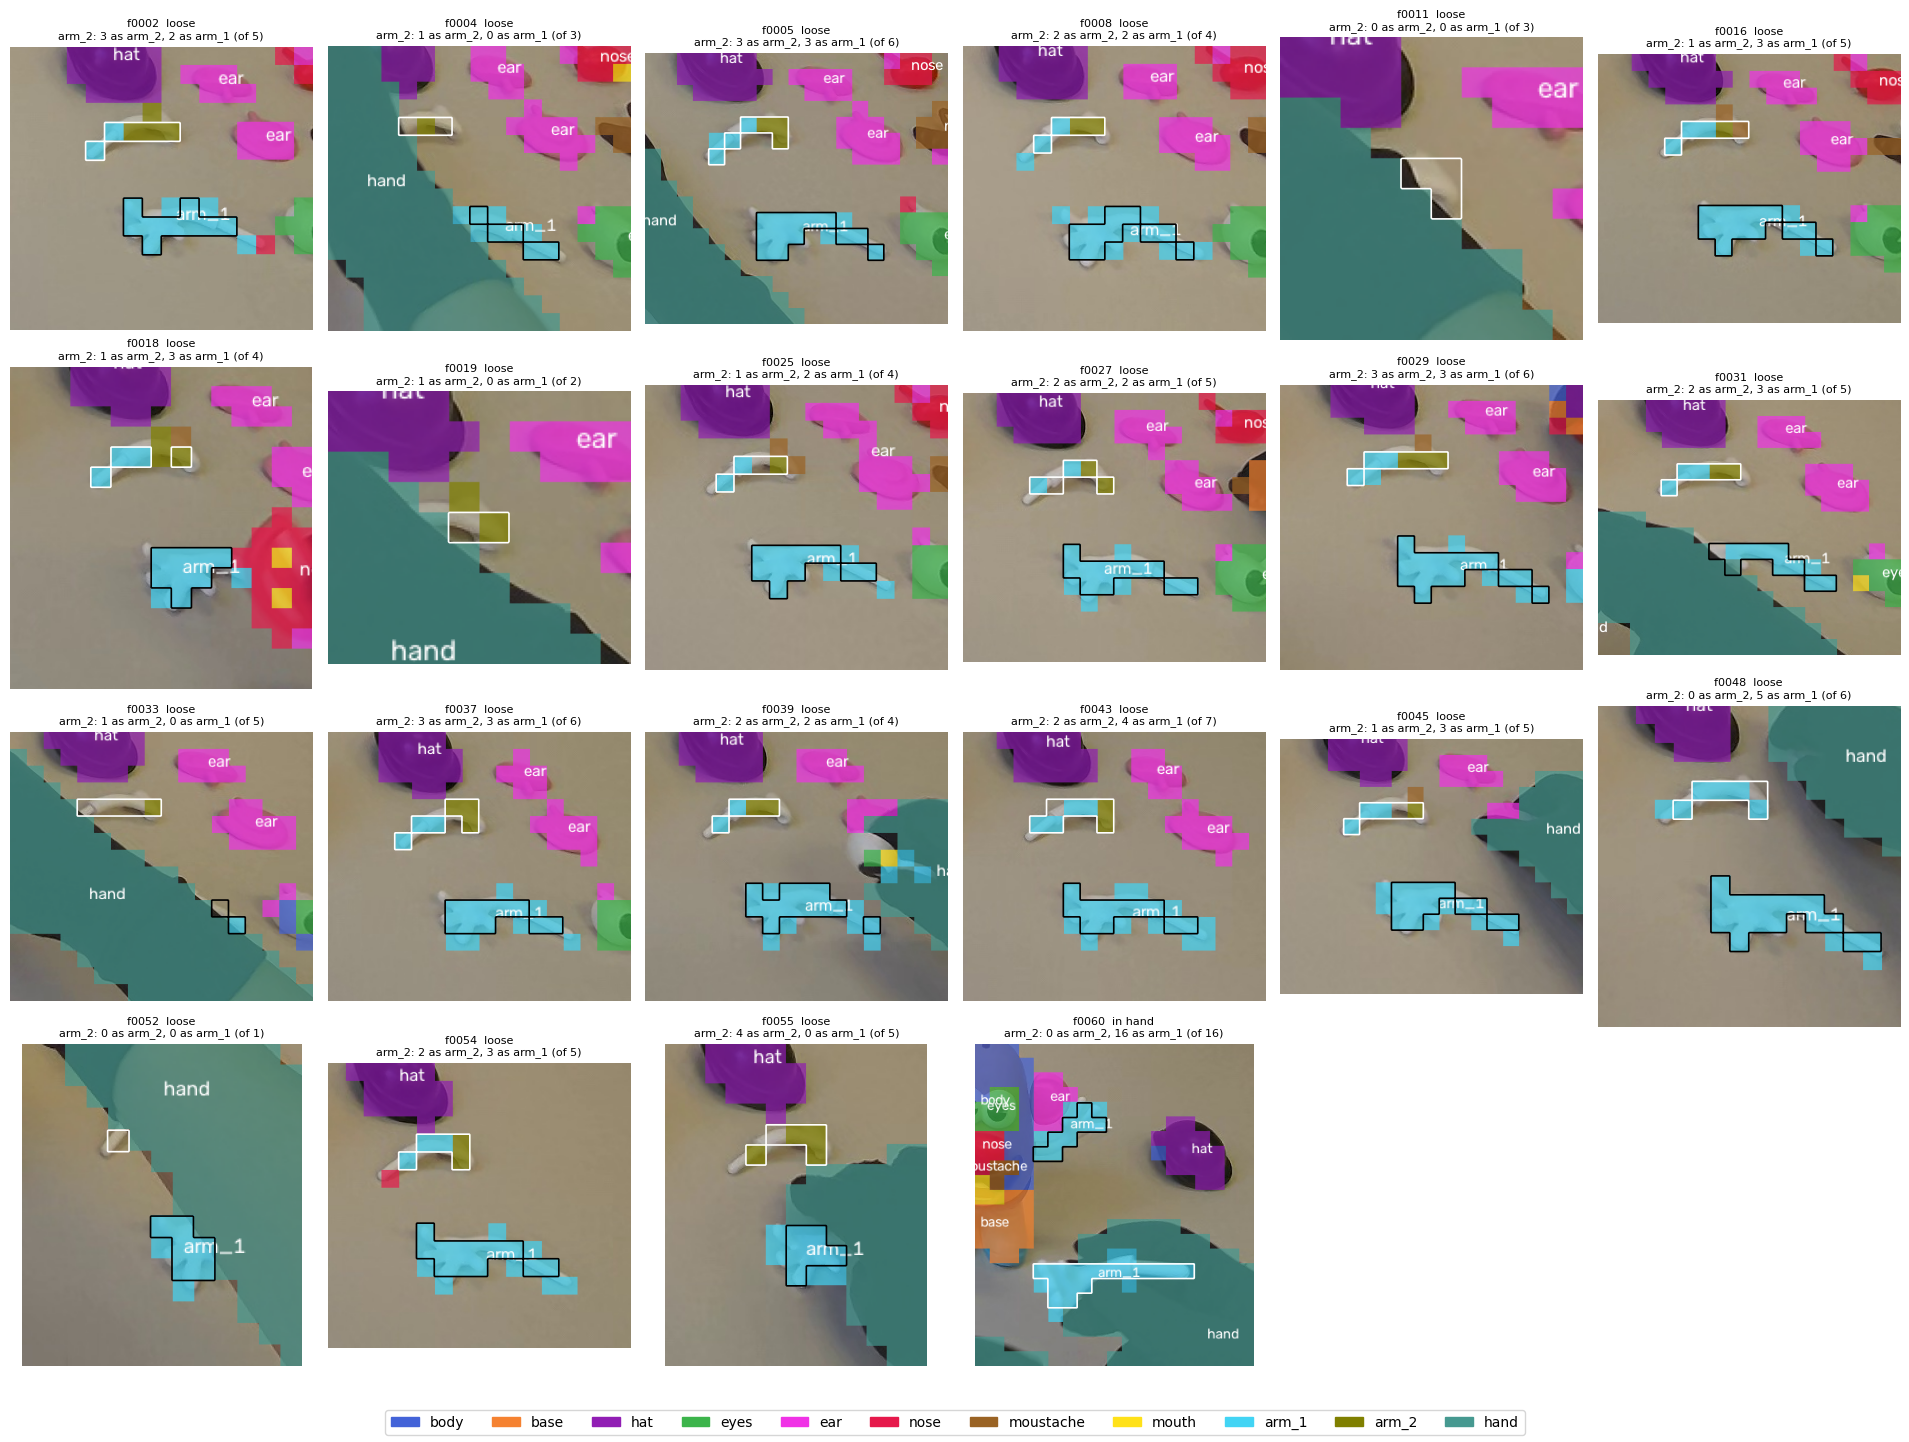

In [12]:
# 4.5 Where A puts arm_1 and arm_2 when arm_2 is loose or in hand (A only, description)
def show_arms(name, frames, cols=6, pad=4):
    """Crop around both arms (ground truth, plus `pad` patches), labels of support set `name` coloured,
    true contours on top: white = arm_2, black = arm_1."""
    rows = int(np.ceil(len(frames) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, frames):
        item = EVAL_FRAMES[k]
        image = np.asarray(Image.open(item["image_path"]).convert("RGB"))
        labels = item["labels"][name]
        overlay = render_overlay(image, labels, MIN_BLOB_PATCHES)

        r, c = np.where(np.isin(item["gt"], [ARM_1, ARM_2]))
        r0, r1 = max(r.min() - pad, 0), min(r.max() + pad + 1, item["gt"].shape[0])
        c0, c1 = max(c.min() - pad, 0), min(c.max() + pad + 1, item["gt"].shape[1])
        ax.imshow(overlay[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
        for cls, color in ((ARM_2, "white"), (ARM_1, "black")):
            mask = (item["gt"] == cls)[r0:r1, c0:c1]
            if mask.any():
                ax.contour(np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE))), levels=[0.5], colors=color, linewidths=1.2)

        on_arm_2 = labels[item["gt"] == ARM_2]
        ax.set_title(f"{item['frame'][-5:]}  {item['states']['arm_2']}\n"
                     f"arm_2: {(on_arm_2 == ARM_2).sum()} as arm_2, {(on_arm_2 == ARM_1).sum()} as arm_1 "
                     f"(of {on_arm_2.size})", fontsize=8)
    legend = [mpatches.Patch(color=CLASS_COLORS[c], label=c) for c in CLASS_NAMES if c != BACKGROUND_LABEL]
    fig.legend(handles=legend, loc="lower center", ncol=11)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


fig = show_arms("A", EARLY)
fig.savefig(OUTPUT_DIR / "arms_early_A.png", dpi=90, bbox_inches="tight")
plt.show()

Observation 4: The states from the event log agree with the rules that chose the frames: every piece of a pick frame is in hand and every piece of a mount frame is mounting, with f0031 in hand. Each piece is in hand in one frame and mounting in one frame, except the ears (2 and 2), the nose (2 in hand) and the moustache (3 in hand). Loose, the hat is present in 26 frames, arm_2 in 21 and arm_1 in 19; the base is never annotated loose, since it is picked outside the frame.

A sees every mounted piece in every frame, except the moustache (15 of 16). Loose, it misses the hat once (25 of 26), the eyes three times (11 of 14), the mouth once (1 of 2) and arm_2 three times (18 of 21). In hand it misses one nose (1 of 2) and arm_2 (0 of 1); at the mounting one ear (1 of 2) and arm_2 (0 of 1).

The candidate margin is 0.779 − 0.765 = 0.014. It corresponds to between 1.9 patches (arm_2) and 18.1 patches (body) over the 31 frames, that is between 0.07 and 0.62 patches per frame where the piece is present.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

configs/assembly_1_events.json: touch, first_seen, insert and hands_off of every piece.

Phase 1 test, Section 3: the rules that chose the frames; f0031 as the join in hand.

Support-set study on V2, Observation 8.2: the mIoU of A on assembly_2, 0.779.

Piaggio et al. 2012, eAppendix ("Choice of the noninferiority margin Δ"): the margin is justified on statistical and practical grounds and fixed in advance.

------------------------------------------------------------------------------------------------------------------------------------------